# 02. 등교·하교·퇴근 시간대 비교

**질문**
1. 평일 등교·하교·퇴근 시간대 중 어느 때가 더 붐비는가?
2. 출발을 30분, 1시간 옮기면 혼잡도는 얼마나 줄어드는가?

**분석 단위**: 평일 **역·방향**(예: 2호선 강남 내선). 같은 역·방향을 여러 시간대에서 반복해서 쟀으므로 **대응(paired) 비교**를 한다.
시간대 정의는 `config.COMMUTE_WINDOWS`를 따른다(등교 07:30–09:30, 하교 16:00–18:00, 퇴근 18:00–20:00).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from subway.load import load_congestion
from subway.clean import clean_congestion
from subway.config import COMMUTE_WINDOWS
from subway.stats import compare_pairs

sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.precision", 3)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
df = clean_congestion(load_congestion(ROOT / "data/raw/서울교통공사_지하철혼잡도정보_20260930.csv"))
wk = df[df.day_type == "평일"]
KEY = ["line", "station_code", "station", "direction"]
COLORS = {"등교": "#4c72b0", "하교": "#55a868", "퇴근": "#c44e52"}

## 1. 시간대별 평균 혼잡도 (역·방향 단위)

In [2]:
windows = pd.DataFrame({
    name: wk[(wk.hour >= s) & (wk.hour < e)].groupby(KEY).congestion.mean()
    for name, (s, e) in COMMUTE_WINDOWS.items()
}).dropna()
print(f"역·방향 {len(windows)}개")
windows.describe(percentiles=[.1, .25, .5, .75, .9]).T.round(1)

역·방향 543개


,count,mean,std,min,10%,25%,50%,75%,90%,max
등교,543.0,50.7,30.3,0.4,14.9,27.5,43.4,72.4,93.9,137.6
하교,543.0,47.6,21.4,0.6,20.9,32.6,45.3,63.1,78.0,111.5
퇴근,543.0,47.7,25.1,0.7,16.8,29.0,44.2,66.0,82.6,114.9


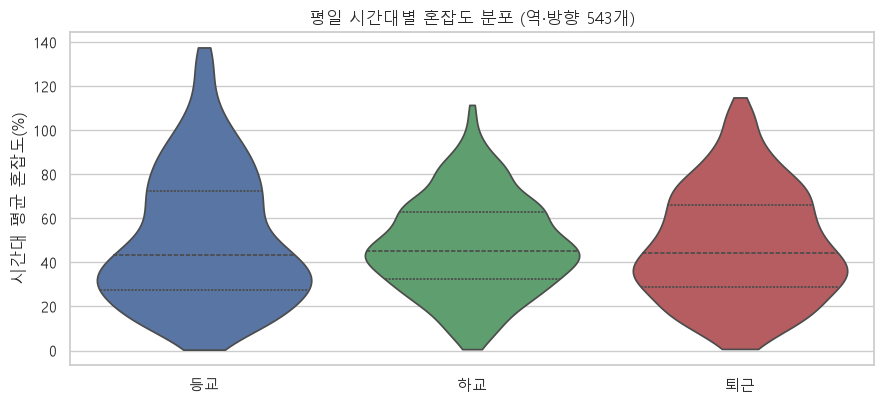

In [3]:
long = windows.melt(var_name="시간대", value_name="혼잡도")
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.violinplot(data=long, x="시간대", y="혼잡도", hue="시간대", palette=COLORS, inner="quartile", cut=0, ax=ax, legend=False)
ax.set(xlabel="", ylabel="시간대 평균 혼잡도(%)", title="평일 시간대별 혼잡도 분포 (역·방향 543개)")
plt.tight_layout(); plt.savefig(FIG / "04_window_distribution.png", dpi=150); plt.show()

세 시간대의 **중앙값은 43~45%로 거의 같다.** 차이는 분포의 모양에 있다.
등교 시간대는 위아래로 넓게 퍼져 있다. 상위 10%는 하교·퇴근보다 훨씬 높고, 하위 25%는 오히려 더 낮다.
아침에는 '도심으로 들어가는 방향'에만 사람이 몰리고 반대 방향은 비어 있다는 뜻이다.

## 2. 대응 비교 검정

In [4]:
pairs = [("등교", "하교"), ("하교", "퇴근"), ("등교", "퇴근")]
result = compare_pairs(windows, pairs)
result.round(3)

,n,평균 차이,중앙값 차이,95% CI 하한,95% CI 상한,a가 더 낮은 비율,효과크기 dz,Wilcoxon p,Holm 보정 p
비교,,,,,,,,,
등교 - 하교,543,3.044,-0.150,-4.700,5.100,0.501,0.083,0.168,0.505
하교 - 퇴근,543,-0.033,1.275,0.400,2.050,0.444,-0.004,0.502,0.505
등교 - 퇴근,543,3.011,0.400,-4.975,6.375,0.495,0.071,0.204,0.505


- 세 쌍 모두 **Holm 보정 p > 0.05**이고, 효과크기 dz도 0.1 미만이다.
- 중앙값 차이의 95% 신뢰구간은 등교−하교 −4.7~5.1%p, 등교−퇴근 −5.0~6.4%p로 0을 포함한다. 하교−퇴근은 0.4~2.1%p로 0을 살짝 벗어나지만, 차이가 1~2%p라 실제로는 체감하기 어렵다.
- 세 쌍 모두 차이가 있더라도 **±6%p 이내**다. 아래 3절에서 볼 '출발을 30분~1시간 옮기는 효과'(7~31%p)보다 훨씬 작다. 따라서 **시간대 평균으로는 의미 있는 차이가 없다**고 본다.
- 'a가 더 낮은 비율'도 50% 안팎이다. 어떤 역·방향은 아침이 더 붐비고, 어떤 곳은 저녁이 더 붐벼서 서로 상쇄된다.

### 같은 데이터를 독립표본으로 검정하면?

역·방향·30분 슬롯 행을 전부 독립된 관측치로 보고 t-검정을 하면 결과가 어떻게 달라지는지 확인한다.

In [5]:
def window_rows(name):
    s, e = COMMUTE_WINDOWS[name]
    return wk[(wk.hour >= s) & (wk.hour < e)].congestion.dropna()

for a, b in pairs:
    x, y = window_rows(a), window_rows(b)
    t = stats.ttest_ind(x, y)
    print(f"{a}(n={len(x)}) vs {b}(n={len(y)}): 평균 차이 {x.mean() - y.mean():+.2f}%p, t={t.statistic:.2f}, p={t.pvalue:.4f}")

등교(n=2172) vs 하교(n=2172): 평균 차이 +3.04%p, t=3.57, p=0.0004
하교(n=2172) vs 퇴근(n=2172): 평균 차이 -0.03%p, t=-0.04, p=0.9671
등교(n=2172) vs 퇴근(n=2172): 평균 차이 +3.01%p, t=3.27, p=0.0011


행 단위로 독립표본 검정을 하면 표본 수가 역·방향 수의 4배로 부풀고, 같은 역·방향의 반복 측정이 서로 독립이라고 가정하게 된다.
실제로 등교−하교는 대응 비교에서 p = 0.17이었는데, 독립표본 t-검정에서는 **p = 0.0004**로 '매우 유의'하게 나온다. 평균 차이는 3%p로 똑같은데 결론만 뒤집힌다.
같은 역에서 시간만 바꿔 잰 값은 **대응 비교로 검정해야 한다.**

## 3. 출발을 30분 옮기면 얼마나 줄어드나

In [6]:
slots = wk.pivot_table(index=KEY, columns="hour", values="congestion")

def shift_effect(ref, hours):
    rows = []
    for h in hours:
        r = compare_pairs(slots.rename(columns=lambda c: f"{c:g}"), [(f"{h:g}", f"{ref:g}")]).iloc[0]
        rows.append({"출발": h, **r.to_dict()})
    out = pd.DataFrame(rows)
    from statsmodels.stats.multitest import multipletests
    out["Holm 보정 p"] = multipletests(out["Wilcoxon p"], method="holm")[1]
    return out

am = shift_effect(8.0, [6.5, 7.0, 7.5, 8.5, 9.0, 9.5])
pm = shift_effect(18.0, [15.5, 16.0, 16.5, 17.0, 17.5, 18.5, 19.0, 19.5])
cols = ["출발", "중앙값 차이", "95% CI 하한", "95% CI 상한", "a가 더 낮은 비율", "Holm 보정 p"]
display(am[cols].round(3)); display(pm[cols].round(3))

,출발,중앙값 차이,95% CI 하한,95% CI 상한,a가 더 낮은 비율,Holm 보정 p
0,6.5,-31.1,-34.5,-29.2,0.996,0.0
1,7.0,-19.0,-20.5,-17.9,0.980,0.0
2,7.5,-7.4,-7.9,-6.8,0.891,0.0
3,8.5,-10.8,-11.9,-9.6,0.904,0.0
4,9.0,-17.7,-19.2,-16.3,0.974,0.0
5,9.5,-23.5,-26.1,-22.1,0.971,0.0


,출발,중앙값 차이,95% CI 하한,95% CI 상한,a가 더 낮은 비율,Holm 보정 p
0,15.5,-22.0,-24.800,-19.5,0.917,0.0
1,16.0,-17.4,-21.200,-14.8,0.834,0.0
2,16.5,-11.9,-15.200,-9.5,0.794,0.0
3,17.0,-8.4,-10.200,-6.9,0.779,0.0
4,17.5,-5.9,-6.500,-4.7,0.808,0.0
5,18.5,-4.4,-5.102,-3.7,0.744,0.0
6,19.0,-19.0,-20.400,-17.4,0.963,0.0
7,19.5,-26.5,-28.300,-24.5,1.000,0.0


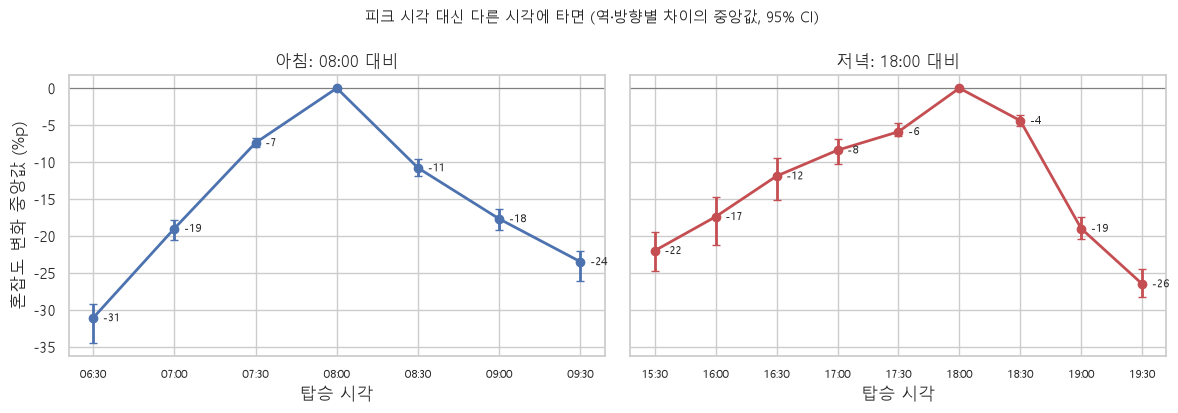

In [7]:
def fmt(h): return f"{int(h):02d}:{int(round(h % 1 * 60)):02d}"

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, tbl, ref, color, title in [(axes[0], am, 8.0, COLORS["등교"], "아침: 08:00 대비"), (axes[1], pm, 18.0, COLORS["퇴근"], "저녁: 18:00 대비")]:
    full = pd.concat([tbl, pd.DataFrame([{"출발": ref, "중앙값 차이": 0, "95% CI 하한": 0, "95% CI 상한": 0}])]).sort_values("출발")
    ax.errorbar(full["출발"], full["중앙값 차이"],
                yerr=[full["중앙값 차이"] - full["95% CI 하한"], full["95% CI 상한"] - full["중앙값 차이"]],
                fmt="o-", color=color, capsize=3, lw=2)
    ax.axhline(0, color="gray", lw=0.8)
    for _, r in full.iterrows():
        if r["출발"] != ref:
            ax.annotate(f"{r['중앙값 차이']:.0f}", (r["출발"], r["중앙값 차이"]), textcoords="offset points", xytext=(7, 0), ha="left", va="center", fontsize=8)
    ax.set_xticks(full["출발"]); ax.set_xticklabels([fmt(h) for h in full["출발"]], fontsize=8)
    ax.set(title=title, xlabel="탑승 시각")
axes[0].set_ylabel("혼잡도 변화 중앙값 (%p)")
fig.suptitle("피크 시각 대신 다른 시각에 타면 (역·방향별 차이의 중앙값, 95% CI)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "05_shift_effect.png", dpi=150); plt.show()

시간대 '평균'으로는 차이가 없었지만, **30분 단위로 보면 차이가 크다.**
- 아침: 08:00 대신 **07:30**에 타면 중앙값 7%p, **07:00**에 타면 19%p 낮아진다. 9시 이후로 미루는 것도 효과가 비슷하다.
- 저녁: 18:00 대신 **17:00**이면 8%p, **16:00**이면 17%p 낮아진다. 18:30은 4%p밖에 줄지 않고, 19:00이 되어야 19%p로 크게 줄어든다.
- 모든 비교가 Holm 보정 후에도 유의하다. 그러나 이 데이터는 표본이 많아서 작은 차이도 유의하게 나오므로, p값보다 **차이의 크기(%p)**를 근거로 삼는다.

## 4. 역·방향마다 피크 시각은 같은가

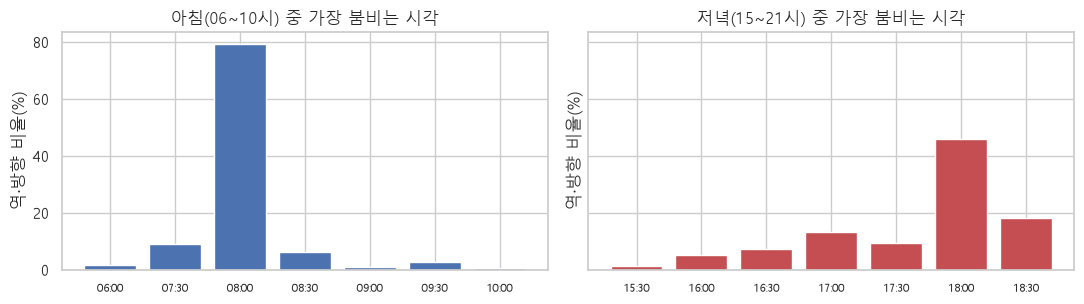

아침 피크가 08:00인 비율: 79% | 저녁 피크가 18:00인 비율: 46%


In [8]:
am_peak = slots.loc[:, 6.0:10.0].idxmax(axis=1).value_counts(normalize=True).sort_index()
pm_peak = slots.loc[:, 15.0:21.0].idxmax(axis=1).value_counts(normalize=True).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, s, color, title in [(axes[0], am_peak, COLORS["등교"], "아침(06~10시) 중 가장 붐비는 시각"), (axes[1], pm_peak, COLORS["퇴근"], "저녁(15~21시) 중 가장 붐비는 시각")]:
    ax.bar([fmt(h) for h in s.index], s.values * 100, color=color)
    ax.set(title=title, ylabel="역·방향 비율(%)"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("아침 피크가 08:00인 비율:", f"{am_peak.get(8.0, 0):.0%}", "| 저녁 피크가 18:00인 비율:", f"{pm_peak.get(18.0, 0):.0%}")

아침 피크는 대부분 역·방향에서 **08:00 한 슬롯**에 몰린다. 그래서 30분만 당겨도 효과가 확실하다.
저녁 피크는 16:30~18:30에 넓게 퍼져 있다. 저녁에는 '몇 시가 좋다'는 일반 규칙보다 **내가 탈 역·방향의 곡선을 직접 보는 것**이 중요하다. 이 점이 이후 경로별 추천 기능이 필요한 이유다.

## 정리

| 질문 | 결과 |
|---|---|
| 등교·하교·퇴근 중 어느 때가 더 붐비나 | 역·방향 단위 평균으로는 **의미 있는 차이 없음**(Holm p > 0.05, dz < 0.1, 차이 ±6%p 이내). 아침은 방향 쏠림이 커서 분포가 더 넓다 |
| 출발을 옮기면 얼마나 줄어드나 | 아침 08:00 → 07:30은 −7%p, 07:00은 −19%p / 저녁 18:00 → 17:00은 −8%p, 16:00은 −17%p (중앙값) |
| 피크 시각은 같은가 | 아침은 79%가 08:00에 집중, 저녁은 16:30~18:30에 분산 |

**한계**
- 같은 노선의 이웃한 역은 서로 비슷하게 움직이므로, 역·방향 543개가 완전히 독립은 아니다. 신뢰구간이 실제보다 좁게 나왔을 수 있다.
- 혼잡도는 30분 동안 지나간 열차들의 평균이다. 같은 슬롯 안에서도 열차마다 차이가 있다.
- 2026년 3분기 한 시점의 데이터다. 방학·시험기간 같은 학사 일정은 반영되지 않았다.

다음 노트북: `03_regression.ipynb`에서 노선·방향·시간대·환승 여부가 혼잡도를 얼마나 설명하는지 회귀로 본다.